In [101]:
from pathlib import Path

import pandas as pd

In [102]:
DATA_PATH = Path("../data/raw/student_data.csv")
df = pd.read_csv(DATA_PATH)
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [103]:
df.shape

(395, 33)

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [105]:
df.isna().sum().sort_values(ascending=False)

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [106]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [107]:
df_encoding = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoding.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


In [108]:
import seaborn as sns
import matplotlib.pyplot as plt

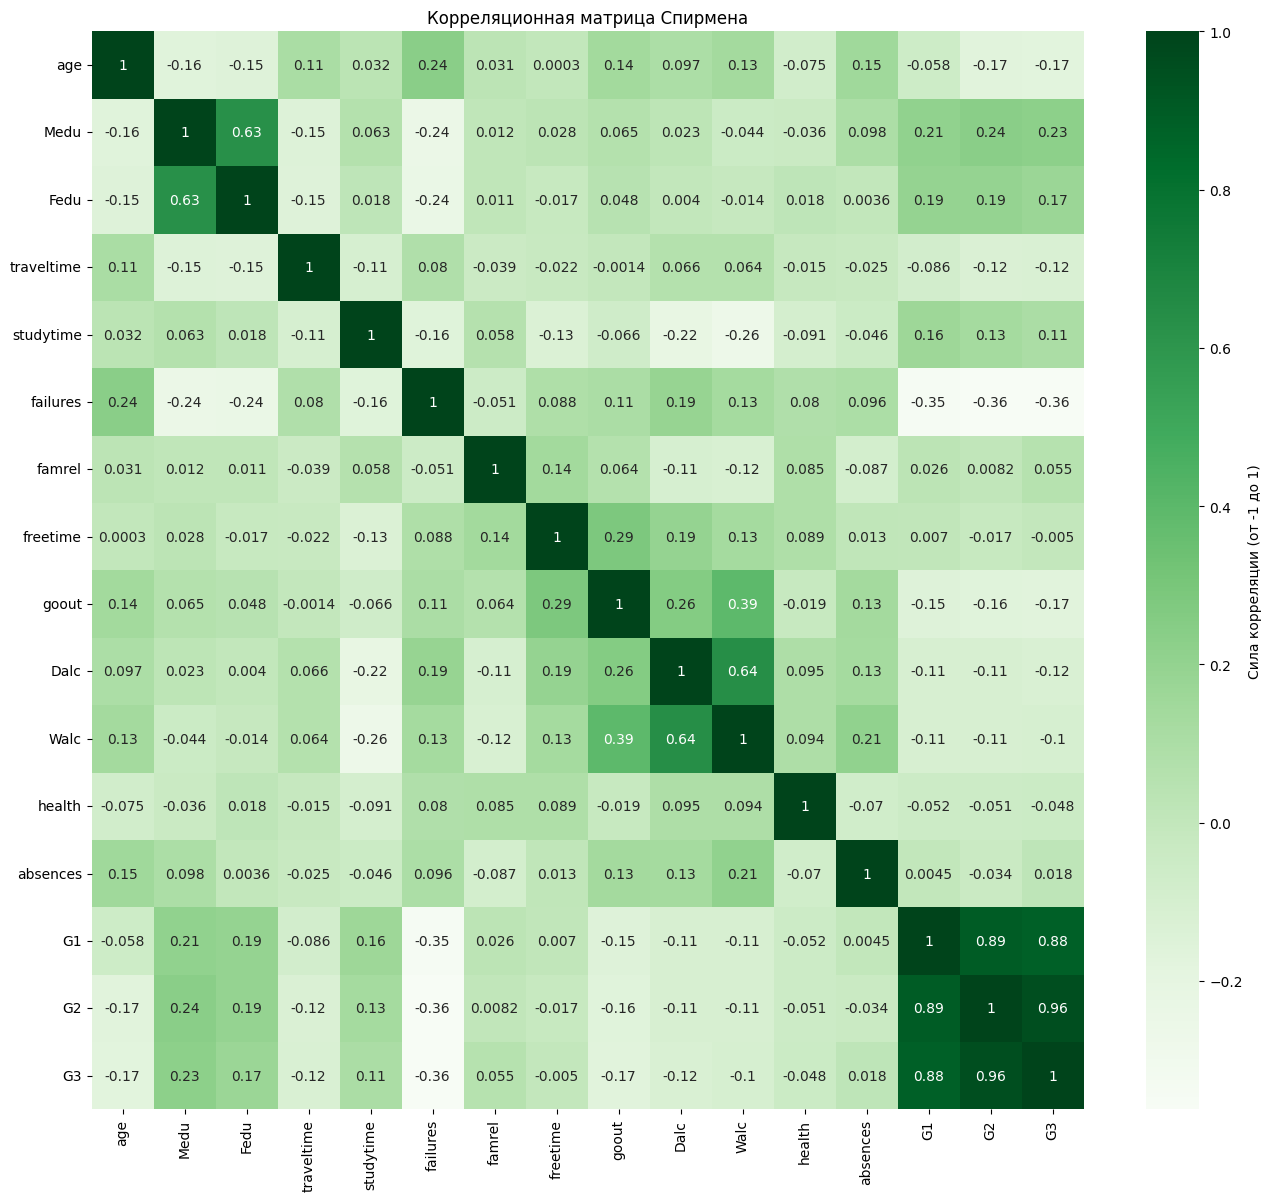

In [109]:
corr_matrix = df.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(16, 14))

# Добавляем параметр cbar_kws с заголовком 'label'
sns.heatmap(corr_matrix, annot=True, cmap='Greens',
            cbar_kws={'label': 'Сила корреляции (от -1 до 1)'})

plt.title("Корреляционная матрица Спирмена")
plt.show()


In [110]:
corr_with_target = corr_matrix["G3"].drop("G3")
corr_with_target.sort_values(ascending=False).head(15).round(3)

G2            0.957
G1            0.878
Medu          0.225
Fedu          0.170
studytime     0.105
famrel        0.055
absences      0.018
freetime     -0.005
health       -0.048
Walc         -0.104
traveltime   -0.121
Dalc         -0.121
goout        -0.166
age          -0.173
failures     -0.361
Name: G3, dtype: float64

In [111]:
corr_with_target_plus = corr_with_target[corr_with_target > 0].sort_values(ascending=False).round(3)
corr_with_target_plus.head(6)

G2           0.957
G1           0.878
Medu         0.225
Fedu         0.170
studytime    0.105
famrel       0.055
Name: G3, dtype: float64

In [112]:
corr_with_target_minus = corr_with_target[corr_with_target < 0].sort_values(ascending=True).round(3)
corr_with_target_minus.head(7)

failures     -0.361
age          -0.173
goout        -0.166
Dalc         -0.121
traveltime   -0.121
Walc         -0.104
health       -0.048
Name: G3, dtype: float64

Text(0, 0.5, 'Количество студентов')

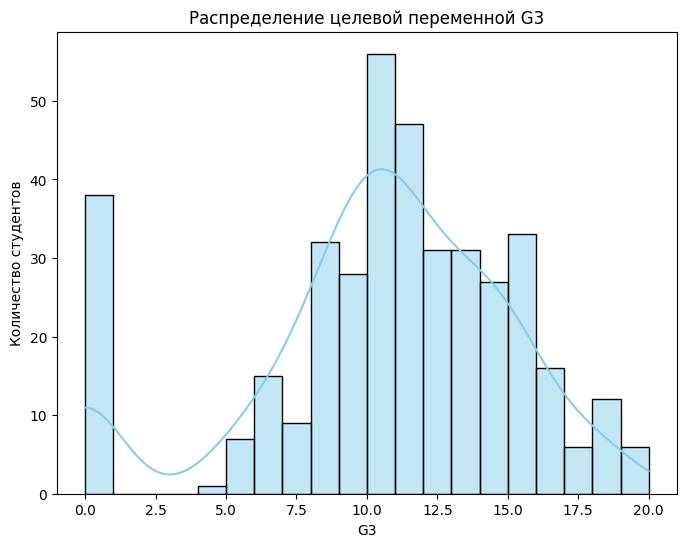

In [113]:
df_g3 = df[["G3"]]
plt.figure(figsize=(8, 6))
sns.histplot(df_g3["G3"], bins=20, kde=True, color="skyblue")
plt.title("Распределение целевой переменной G3")
plt.xlabel("G3")
plt.ylabel("Количество студентов")

In [116]:
df["G3"].describe()

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

In [121]:
df.groupby("failures")["G3"].mean()

failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64

In [120]:
df.groupby("studytime")["G3"].mean()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

In [119]:
df.groupby("higher")["G3"].mean()

higher
no      6.800
yes    10.608
Name: G3, dtype: float64

In [122]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score